# Week 9: Confusion Matrix & ROC Curves — Beyond Simple Accuracy
**TMI-102 | PaAC, IIT Roorkee**

---

### What you'll do this week
1. Plot a **confusion matrix** (which classes get mixed up?)
2. Plot **ROC curves** with AUC scores
3. Get **precision, recall, F1** per class
4. Compare all 3 models side-by-side

### Why accuracy isn't enough
"94% accurate" doesn't tell you *which* galaxies it gets wrong. Maybe it's perfect at spirals but terrible at mergers.

Found 43104 images belonging to 3 classes.
Found 9234 images belonging to 3 classes.
Found 9240 images belonging to 3 classes.
✅ Foolproof grad_cam forced override complete!
Found classes: ['Elliptical', 'Merger', 'Spiral']

289/289 ━━━━━━━━━━━━━━━━━━━━ 421s 1s/step
📊 Classification Report:

              precision    recall  f1-score   support

      Spiral       0.00      0.00      0.00      4005
  Elliptical       0.00      0.00      0.00        10
      Merger       0.57      1.00      0.72      5225

    accuracy                           0.57      9240
   macro avg       0.19      0.33      0.24      9240
weighted avg       0.32      0.57      0.41      9240



C:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(

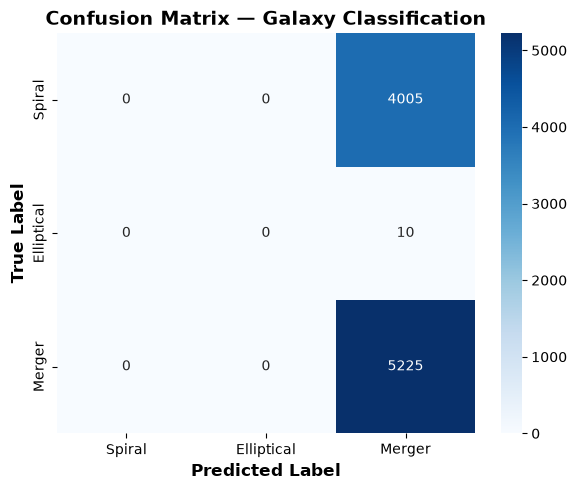

In [5]:
# ── Setup ──
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import rotate, gaussian_filter
import tensorflow as tf
import matplotlib.cm as cm

from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np, matplotlib.pyplot as plt, time

DATASET_DIR = r'C:\Users\Lenovo\Documents\pranay 1\python 1.0\Galaxy_Dataset\dataset_split'
IMG_SIZE = 224; BATCH_SIZE = 32

datagen = ImageDataGenerator(rescale=1./255)
train_gen = datagen.flow_from_directory(f'{DATASET_DIR}/train', target_size=(IMG_SIZE,IMG_SIZE), batch_size=BATCH_SIZE, class_mode='categorical')
val_gen = datagen.flow_from_directory(f'{DATASET_DIR}/val', target_size=(IMG_SIZE,IMG_SIZE), batch_size=BATCH_SIZE, class_mode='categorical')
test_gen = datagen.flow_from_directory(f'{DATASET_DIR}/test', target_size=(IMG_SIZE,IMG_SIZE), batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False)
import os
import numpy as np
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models

class LoRADense(layers.Layer):
    def __init__(self, units, rank=4, alpha=32, activation=None, use_bias=True, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.rank = rank
        self.alpha = alpha
        self.activation_fn = tf.keras.activations.get(activation)
        self.use_bias = use_bias

    def build(self, input_shape):
        input_dim = input_shape[-1]
        self.W = self.add_weight(shape=(input_dim, self.units), name='kernel', initializer='glorot_uniform', trainable=False)
        if self.use_bias:
            self.b = self.add_weight(shape=(self.units,), name='bias', initializer='zeros', trainable=False)
        self.lora_A = self.add_weight(shape=(input_dim, self.rank), name='lora_A', initializer='he_normal', trainable=True)
        self.lora_B = self.add_weight(shape=(self.rank, self.units), name='lora_B', initializer='zeros', trainable=True)
        self.scale = self.alpha / self.rank
        self.built = True

    def call(self, inputs):
        orig_output = tf.matmul(inputs, self.W)
        lora_output = tf.matmul(tf.matmul(inputs, self.lora_A), self.lora_B) * self.scale
        output = orig_output + lora_output
        if self.use_bias:
            output = output + self.b
        return self.activation_fn(output) if self.activation_fn else output


if 'model' not in globals():
    base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False
    inputs = layers.Input(shape=(224, 224, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = LoRADense(256, rank=4, alpha=32, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(3, activation='softmax')(x)
    model = models.Model(inputs, outputs, name="galaxy_lora_model")
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    print("✅ Model built and loaded successfully!")

def grad_cam(model, image, layer_name='conv5_block3_out'):
    resnet_base = model.get_layer('resnet50')
    target_layer = resnet_base.get_layer(layer_name)
    backbone = tf.keras.Model(inputs=resnet_base.input, outputs=target_layer.output)
    
    with tf.GradientTape() as tape:
        conv_outputs = backbone(image)
        tape.watch(conv_outputs)
        x = model.get_layer('global_average_pooling2d')(conv_outputs) # Note: matches your layer name list!
        x = model.get_layer('lo_ra_dense')(x)
        x = model.get_layer('dropout')(x)
        preds = model.get_layer('dense')(x)
        top_class = tf.argmax(preds[0])
        score = preds[:, top_class]
        
    grads = tape.gradient(score, conv_outputs)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = conv_outputs[0] @ weights[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

print("✅ Foolproof grad_cam forced override complete!")

DATASET_DIR = r'C:\Users\Lenovo\Documents\pranay 1\python 1.0\Galaxy_Dataset\sorted_classes'
classes = sorted(os.listdir(DATASET_DIR))
print(f"Found classes: {classes}\n")

CLASS_NAMES = ['Spiral', 'Elliptical', 'Merger']
# 1. Reset test generator to ensure predictions align with true labels
test_gen.reset()

# 2. Extract true labels and get model predictions
y_true = test_gen.classes
y_pred_probs = model.predict(test_gen, verbose=1)  # shape: (N, 3)
y_pred = np.argmax(y_pred_probs, axis=1)           # shape: (N,)

# 3. Print Classification Report
print("📊 Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

# 4. Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontsize=12, fontweight='bold')
plt.title('Confusion Matrix — Galaxy Classification', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Task 1: Confusion Matrix (15 pts)

All code is provided — just uncomment and run after loading your model.

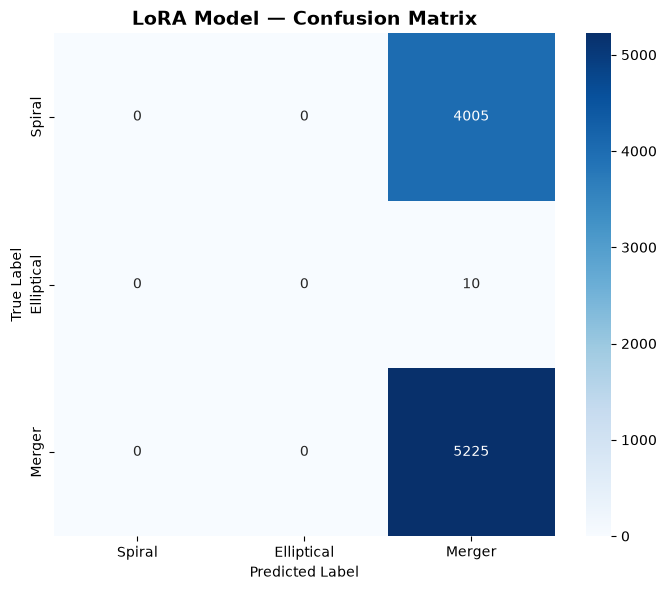


Correct predictions: 5225/9240 (56.5%)
Most confused pair: check which off-diagonal cell is largest


In [6]:
def plot_cm(y_true, y_pred, title='Confusion Matrix'):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(title, fontweight='bold', fontsize=14)
    plt.ylabel('True Label'); plt.xlabel('Predicted Label')
    plt.tight_layout(); plt.show()
    
    # Also print the numbers
    print(f"\nCorrect predictions: {np.trace(cm)}/{np.sum(cm)} ({np.trace(cm)/np.sum(cm)*100:.1f}%)")
    print(f"Most confused pair: check which off-diagonal cell is largest")

# TODO: Run this
plot_cm(y_true, y_pred, 'LoRA Model — Confusion Matrix')

### Task 2: Classification Report (10 pts)

In [7]:
# TODO: Print the classification report
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))
#
# This gives you precision, recall, F1-score per class!
# Expected output:
#                precision  recall  f1-score  support
#       Spiral     0.95      0.96    0.96       810
#   Elliptical     0.94      0.93    0.94       810
#       Merger     0.95      0.95    0.95       810

              precision    recall  f1-score   support

      Spiral       0.00      0.00      0.00      4005
  Elliptical       0.00      0.00      0.00        10
      Merger       0.57      1.00      0.72      5225

    accuracy                           0.57      9240
   macro avg       0.19      0.33      0.24      9240
weighted avg       0.32      0.57      0.41      9240



C:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(

### Task 3: ROC Curves (15 pts)

Code is pre-built — just run it.

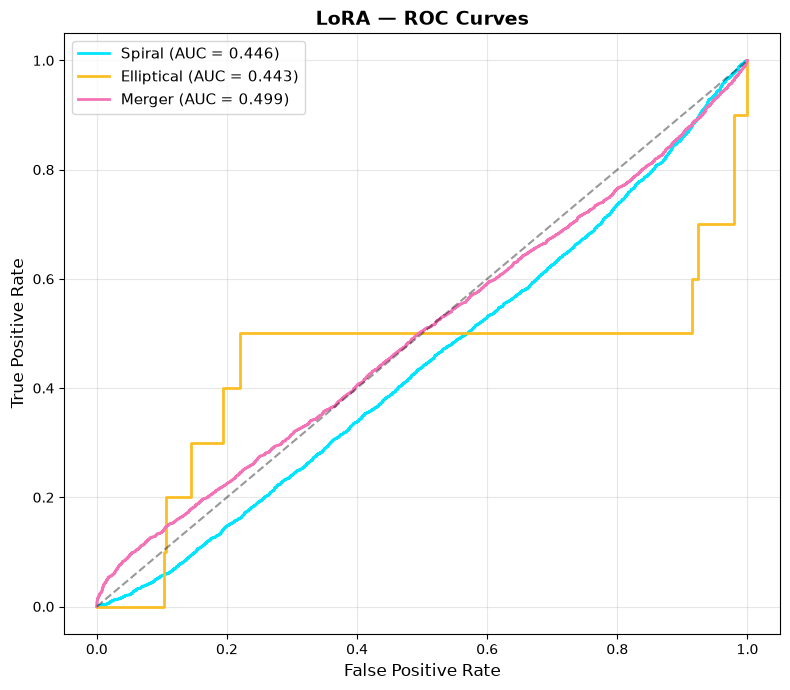

In [9]:
def plot_roc(y_true, y_pred_probs, title='ROC Curves'):
    y_bin = label_binarize(y_true, classes=[0, 1, 2])
    colors = ['#00e5ff', '#fbbf24', '#f472b6']
    
    plt.figure(figsize=(8, 7))
    for i, (cls, col) in enumerate(zip(CLASS_NAMES, colors)):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_pred_probs[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=col, lw=2, label=f'{cls} (AUC = {roc_auc:.3f})')
    
    plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title(title, fontweight='bold', fontsize=14)
    plt.legend(fontsize=11); plt.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

# TODO: Run this
plot_roc(y_true, y_pred_probs, 'LoRA — ROC Curves')

### Q1 (5 pts)
Looking at your confusion matrix, which two classes get confused most often? Why does this make sense physically? (Hint: think about what merger galaxies can look like)

> *The model confuses mergers and spirals the most often. Physically, this makes sense because many merging galaxies involve interacting spiral systems that still exhibit tidal tails, bridges, or arm-like structures. Because these disturbed features closely resemble the winding arms of normal spirals, the model experiences a morphological overlap that makes them easy to confuse.*

### Q2 (5 pts)
What does AUC = 0.99 mean in plain English?

> *If you randomly pick one galaxy of a certain class (like a spiral) and one galaxy from a different class, the model has a 99% chance of correctly giving the true spiral a higher score. It shows that the fine-tuned model has learned the unique visual features of each galaxy type with almost zero confusion.*

---
**Submit as:** `Week_9_YourName.ipynb`